In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from joblib import Parallel, delayed
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
import batman
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import *
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
from HItargets_utils import *

# Exoplanet Archive aggregate (not used here since the bias maps moved to Bias_Maps.ipynb)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

In [2]:
# Target planet: from the NASA Exoplanet Archive, or a CUSTOM entry in HItargets_utils (K2-141 b: Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("TOI-2431 b") # "K2-141 b", "TOI-2431 b"
period, incl, ecc, w, rp, r2, a, T_eff, a_AU = planet.args

u, u_bol = DEFAULT_U, DEFAULT_U_BOL   # transit and irradiance limb darkening (baseline settings, HItargets_utils.py)

In [3]:
# Albedos (baseline settings, HItargets_utils.py)
A_B = DEFAULT_A_B                         # Bond albedo: sets the temperature map
A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B

In [4]:
# Filter to be used
instrument = "MIRI/LRS" # "JWST_NIRSpec.G395H_NRS1"  # "MIRI/LRS"
lrs_path = filter_loc(instrument)
lrs_range = filter_lambda(instrument)

## Detectability and parameter bias analysis

The detection error per minute comes from PandExo for the planet and instrument set above (printed below). For comparison, K2-141 b has 99.2 ppm per minute (PandExo, MIRI/LRS 5.0–10.5 µm).


In [5]:
n_bins = DEFAULT_N_BINS # number of bins in one orbit
minutes_binning = period*24*60/n_bins # bin width [minutes]
sigma_1min = rms_1min(planet, instrument)
n_orbits = DEFAULT_N_ORBITS # number of orbits observed


l1, l2 = lrs_range

A_B_true = A_B  # injected Bond albedo of the hyperillumination truth

# context for the bias-analysis functions imported from simple_bias_analysis.py (fit ranges A_B_FIT_BOUNDS, F_BOUNDS by default: A_B_fit may go below 0)
cfg = FittingConfig(planet=planet, filter_path=lrs_path,
                 l1=l1, l2=l2, A_=A_model,
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins,
                 reflected=True, u_bol=u_bol, u=u)


sigma_bin = cfg.sigma_bin # [ppm]
print(f"\nNoise Level (1min) = {sigma_1min:.1f} ppm")
print(f"period = {period*24*60:.1f} min -> {n_bins} bins of {minutes_binning:.1f} min")
print(f"1-sigma per bin = {sigma_bin:.1f} ppm")

TOI-2431 b [MIRI/LRS]: sigma_1min = 62.93 ppm/min from the PandExo cache (pandexo_cache.csv)

Noise Level (1min) = 62.9 ppm
period = 322.8 min -> 27 bins of 12.0 min
1-sigma per bin = 8.1 ppm


### 1. Pure Detectability

In [6]:
# Full phase curve (reflected + thermal). The naive curve uses full_PhaseCurve(insolation_model="naive")
t_k, pc_k, fp_k = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="hyperillum", u_bol=u_bol)
t_n, pc_n, fp_n = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="naive", u_bol=u_bol)

# Transit removed (phase modulation + occultation only) = reflected(no transit) + thermal(no transit), so the modulation is visible
_, lc_k, _ = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="hyperillum", u_bol=u_bol, include_transit=False)
_, lc_n, _ = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="naive",      u_bol=u_bol, include_transit=False)

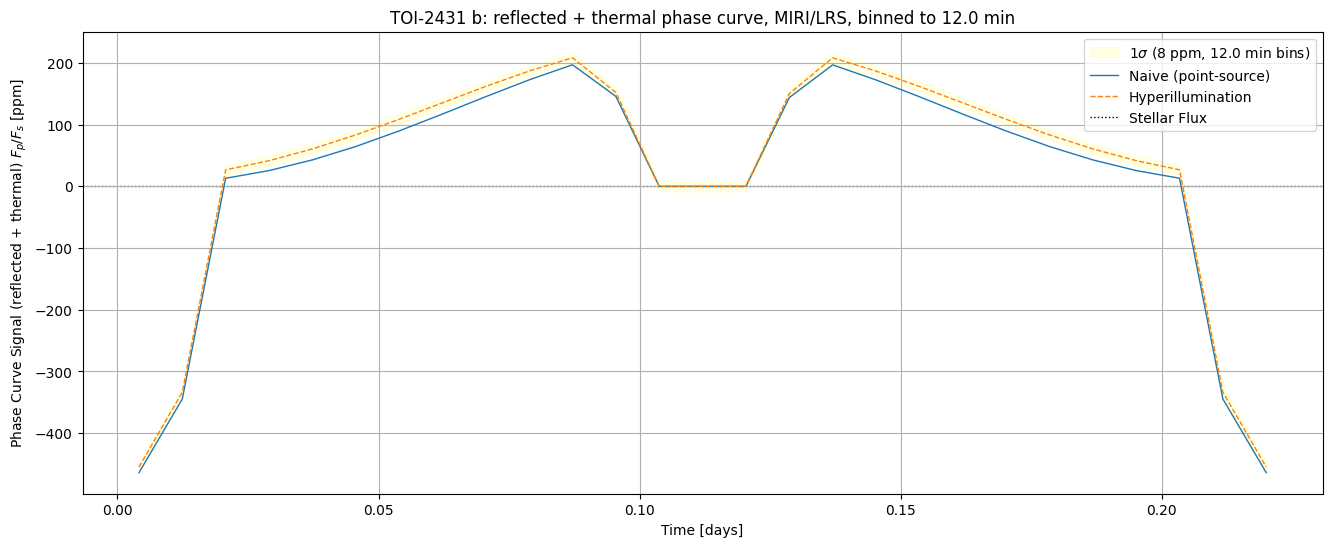

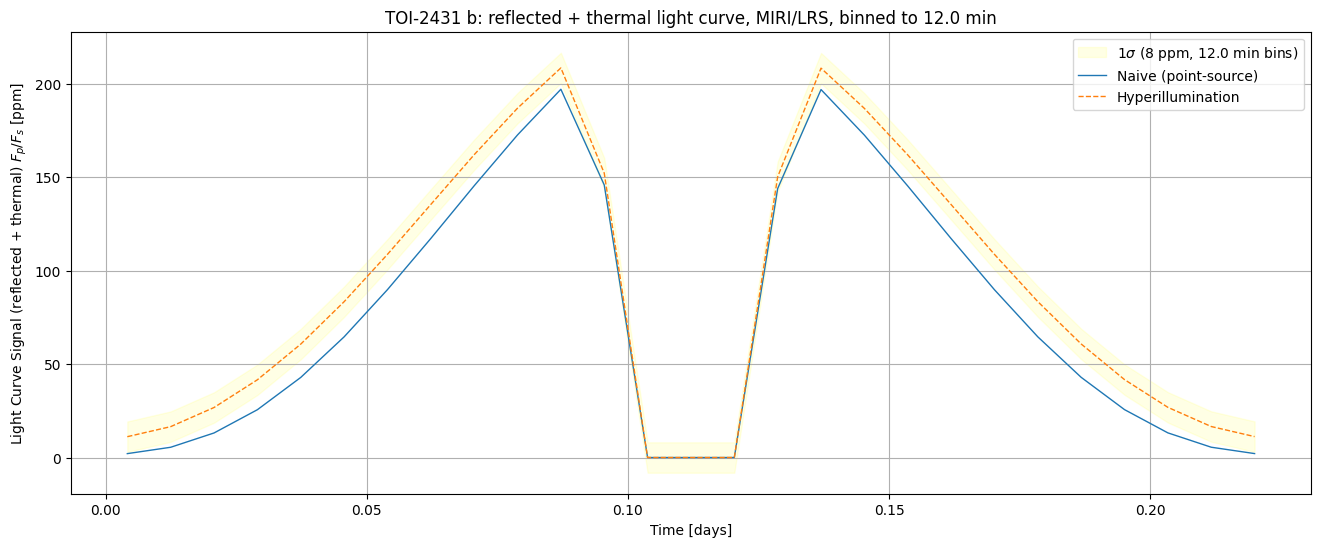

In [7]:
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color="yellow", alpha=0.1, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning:.1f} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")
stellar_flux_line()

plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal phase curve, {instrument}, binned to {minutes_binning:.1f} min")
plt.legend(); plt.grid()
plt.show()

tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color="yellow", alpha=0.1, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning:.1f} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal light curve, {instrument}, binned to {minutes_binning:.1f} min")
plt.legend(); plt.grid()
plt.show()

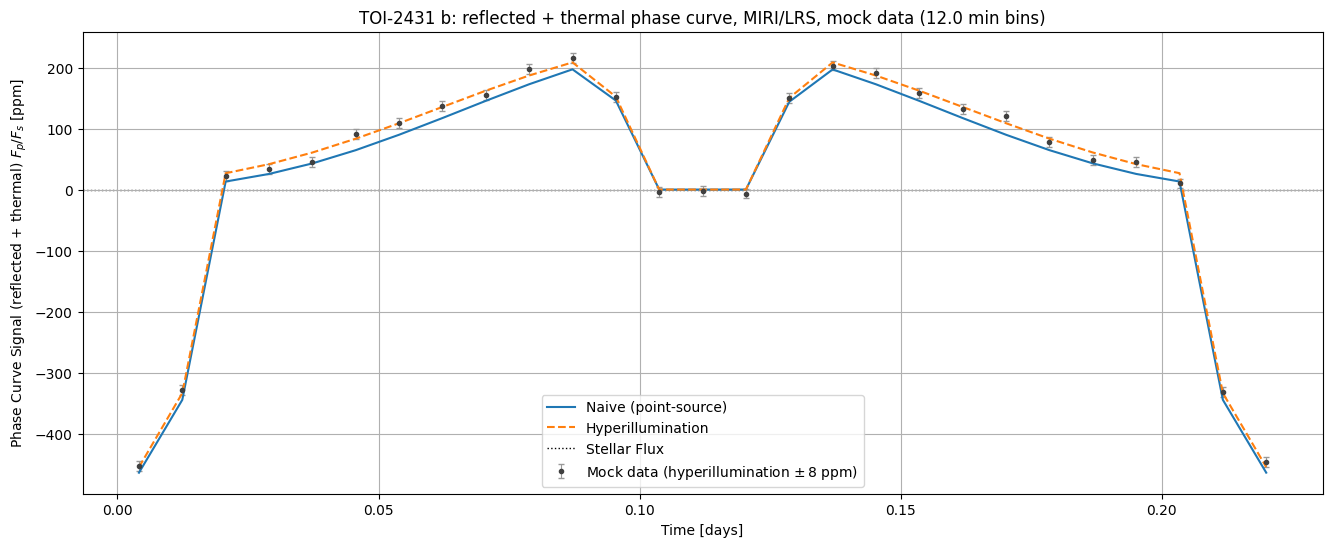

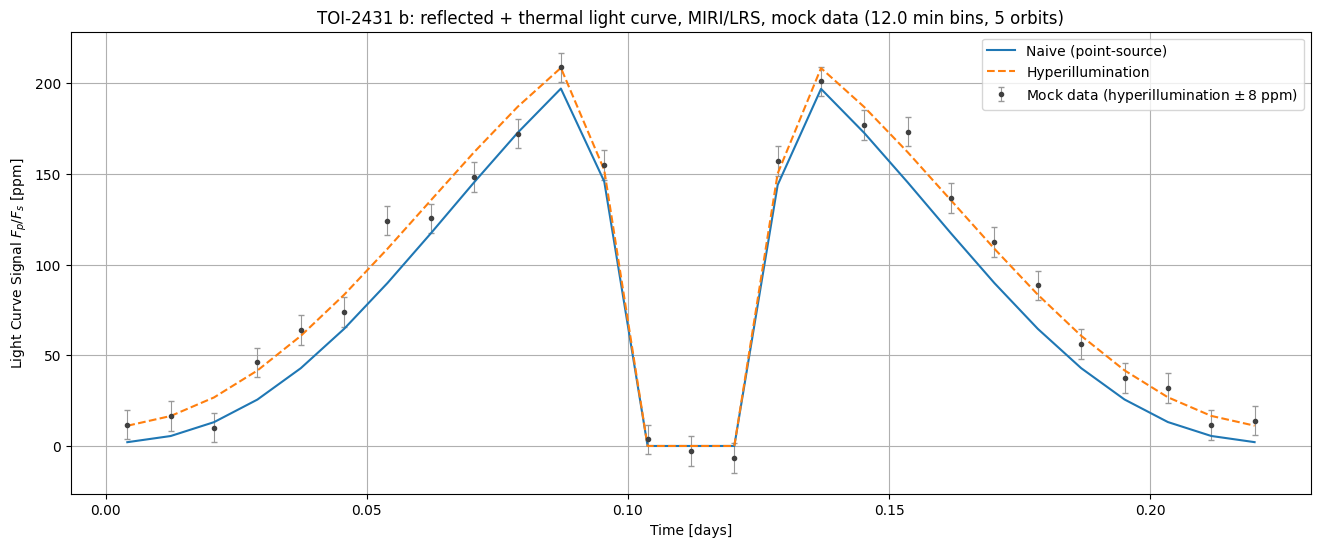

In [8]:
# Mock observation: at each binned time draw a data point ~ N(mean = hyperillum model, std = sigma_bin),
rng = np.random.default_rng(43)   # fixed seed -> reproducible mock data

# --- Phase curve ---
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)   # naive model, binned [ppm]
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)   # hyperillumination model, binned [ppm]
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)        # mock data ~ N(hyperillum, sigma_bin)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
stellar_flux_line()
plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal phase curve, {instrument}, mock data ({minutes_binning:.1f} min bins)")
plt.legend(); plt.grid()
plt.show()

# --- Light curve ---
tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal light curve, {instrument}, mock data ({minutes_binning:.1f} min bins, {n_orbits} orbits)")
plt.legend(); plt.grid()
plt.show()

### 2. Bias in recovered Bond albedo when hyperillumination is neglected - 1-Parameter Fit

In [9]:
# demo: fit the naive model to the hyperillumination truth and report the recovered-A_B bias
_, truth = model_pcurve(cfg, "hyperillum", A_B_true)

for free_offset in (True, False):
    A_fit, chi2, rms = fit_naive(cfg, truth, free_offset=free_offset)
    print(f"A_B: {A_B_true:.3f} -> {A_fit:.3f}  bias={A_fit-A_B_true:+.3f} "
          f"({100*(A_fit-A_B_true)/A_B_true:+.1f}%)  chi2={chi2:.3f}  "
          f"resid_rms={rms:.2f} ppm  significance={np.sqrt(chi2):.2f} sigma "
          f"({cfg.n_orbits} orbits, {cfg.n_bins} bins)")

A_B: 0.200 -> 0.140  bias=-0.060 (-29.9%)  chi2=12.635  resid_rms=5.57 ppm  significance=3.55 sigma (5 orbits, 27 bins)
A_B: 0.200 -> -0.053  bias=-0.253 (-126.5%)  chi2=32.778  resid_rms=8.97 ppm  significance=5.73 sigma (5 orbits, 27 bins)


free offset="False" not really meaningful since normalization has error...

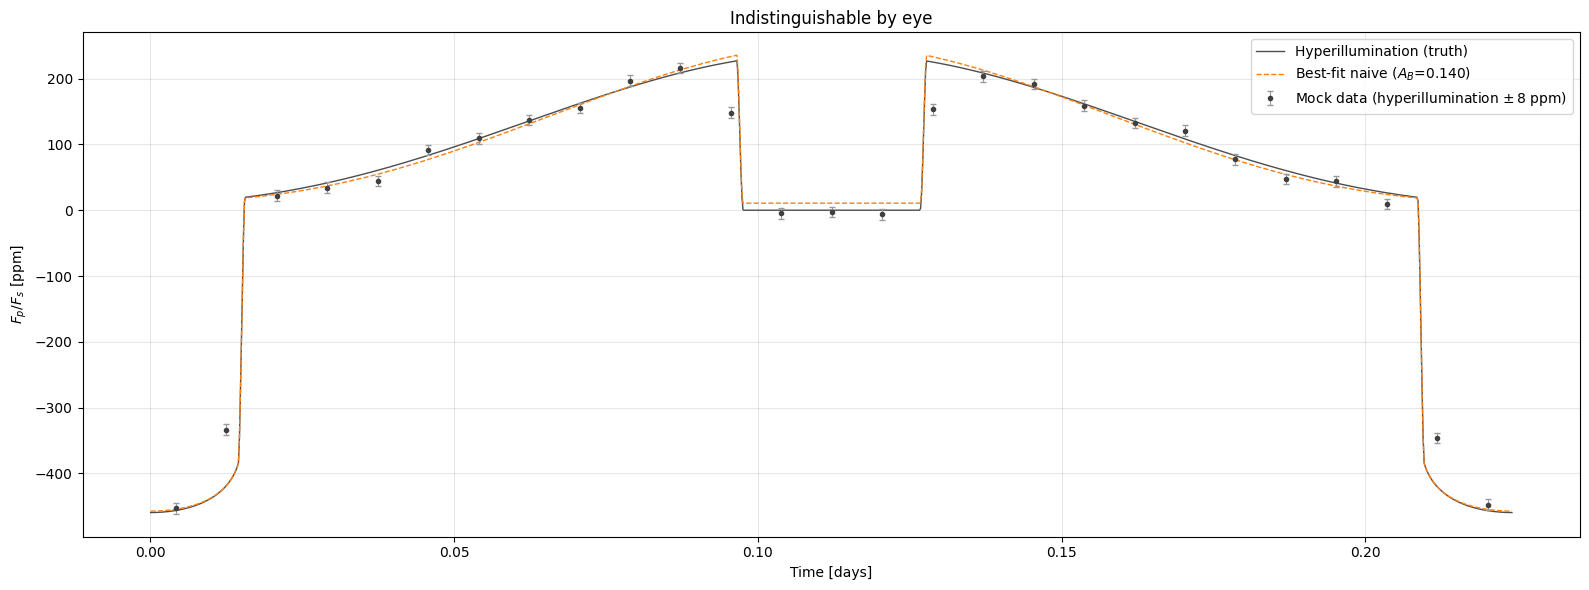

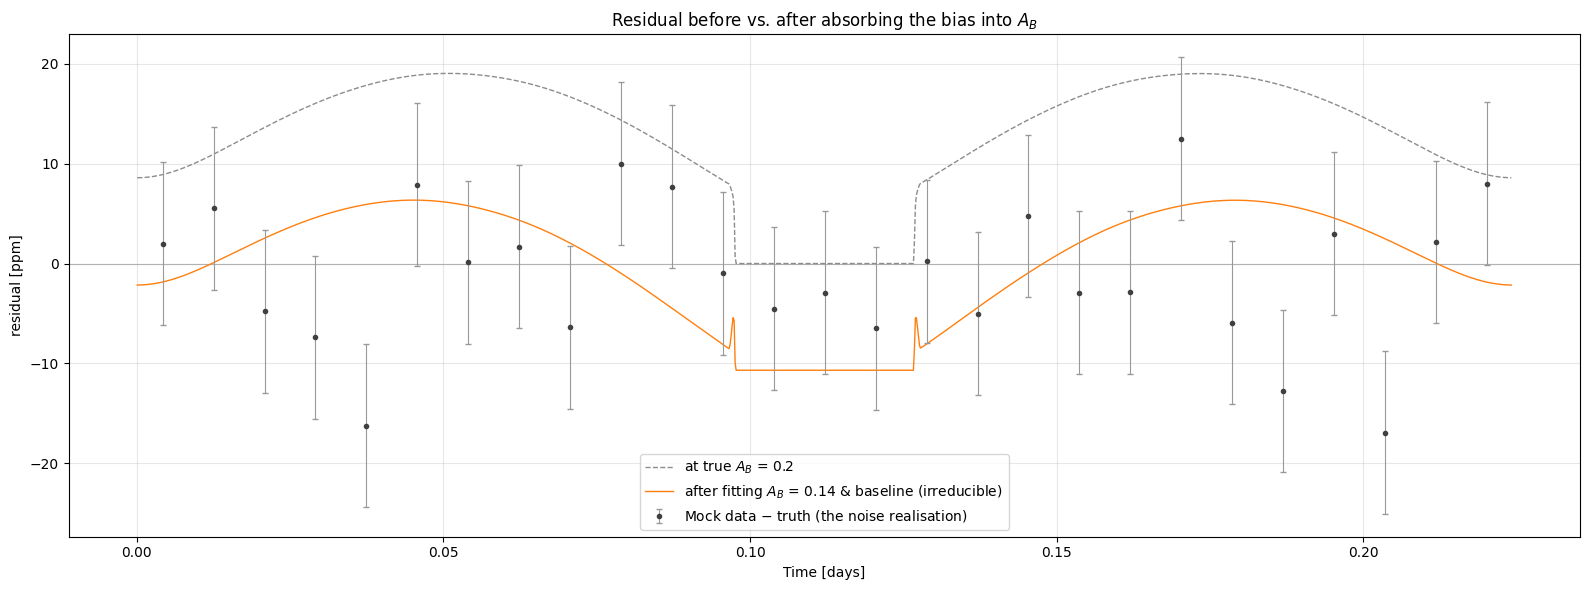

In [10]:
# before vs after absorbing the bias into A_B
t_, truth = model_pcurve(cfg, "hyperillum", A_B_true)
A_fit, _, _  = fit_naive(cfg, truth)
naive_0   = model_pcurve(cfg, "naive", A_B_true)[1]
naive_f   = model_pcurve(cfg, "naive", A_fit)[1]
naive_f   = naive_f + (truth - naive_f).mean()

# Mock observation, as in 1.: one draw ~ N(mean = hyperillumination truth, std = sigma_bin) per bin
tb, yb_truth = bin_curve(t_, truth, minutes_binning)
y_data = yb_truth + np.random.default_rng(43).normal(0., sigma_bin, size=yb_truth.size)   # same seed as the mock data in 1.
mock_kw = dict(fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2, zorder=5)

# Figure 1: truth vs best-fit naive
fig, ax = plt.subplots(figsize=(16, 6))
ax.errorbar(tb, y_data, yerr=sigma_bin, label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)", **mock_kw)
ax.plot(t_, truth,   lw=1, color="0.3", label="Hyperillumination (truth)")
ax.plot(t_, naive_f, lw=1, ls="--", color="C1", label=f"Best-fit naive ($A_B$={A_fit:.3f})")
ax.set_ylabel(r"$F_p/F_s$ [ppm]"); ax.set_xlabel("Time [days]")
ax.set_title("Indistinguishable by eye")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout()
plt.show()

# Figure 2: both residuals combined on one axes, with the same mock data as the noise the bias has to beat
fig, ax = plt.subplots(figsize=(16, 6))
ax.axhline(0., color="0.7", lw=.8, zorder=1)
ax.errorbar(tb, y_data - yb_truth, yerr=sigma_bin, label=r"Mock data $-$ truth (the noise realisation)", **mock_kw)
ax.plot(t_, truth - naive_0, lw=1, ls="--", color="0.55", label=rf"at true $A_B$ = {A_B_true:.1f}")
ax.plot(t_, truth - naive_f, lw=1, color="C1", label=rf"after fitting $A_B$ = {A_fit:.2f} & baseline (irreducible)")
ax.set_ylabel("residual [ppm]"); ax.set_xlabel("Time [days]")
ax.set_title(r"Residual before vs. after absorbing the bias into $A_B$")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout()
plt.show()

### 3. Bias vs. true Bond albedo $A_B$

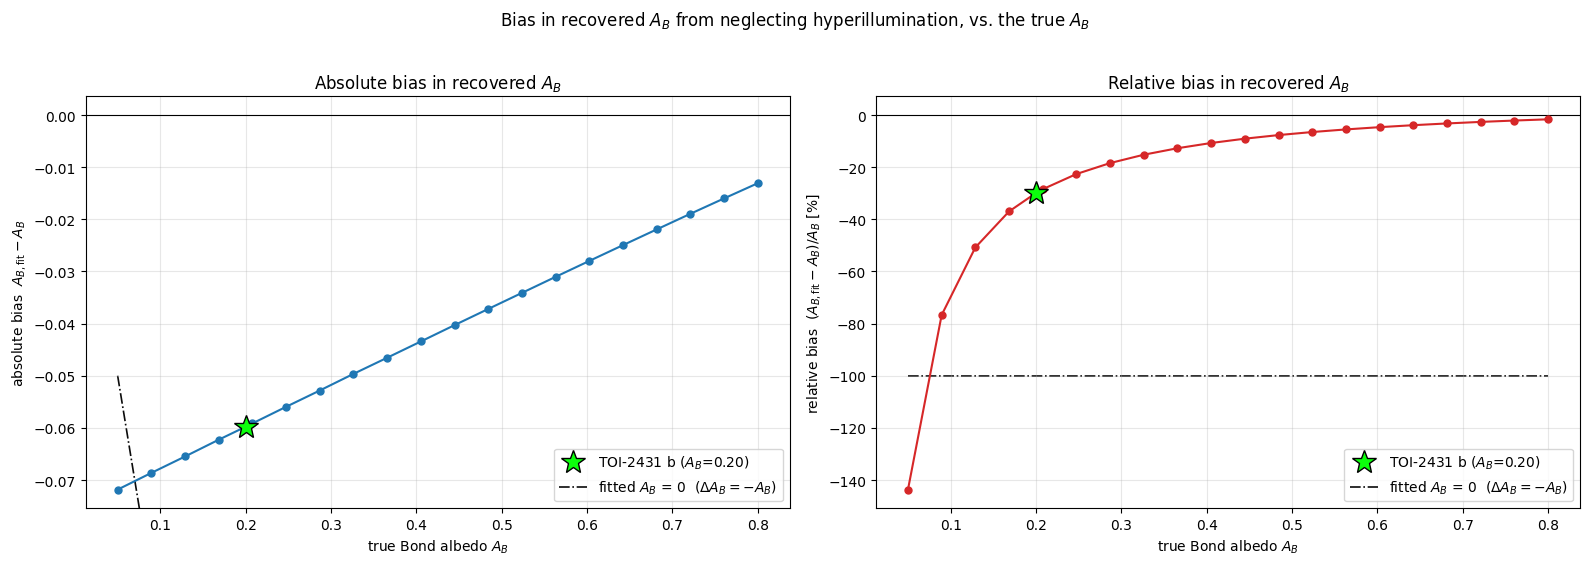

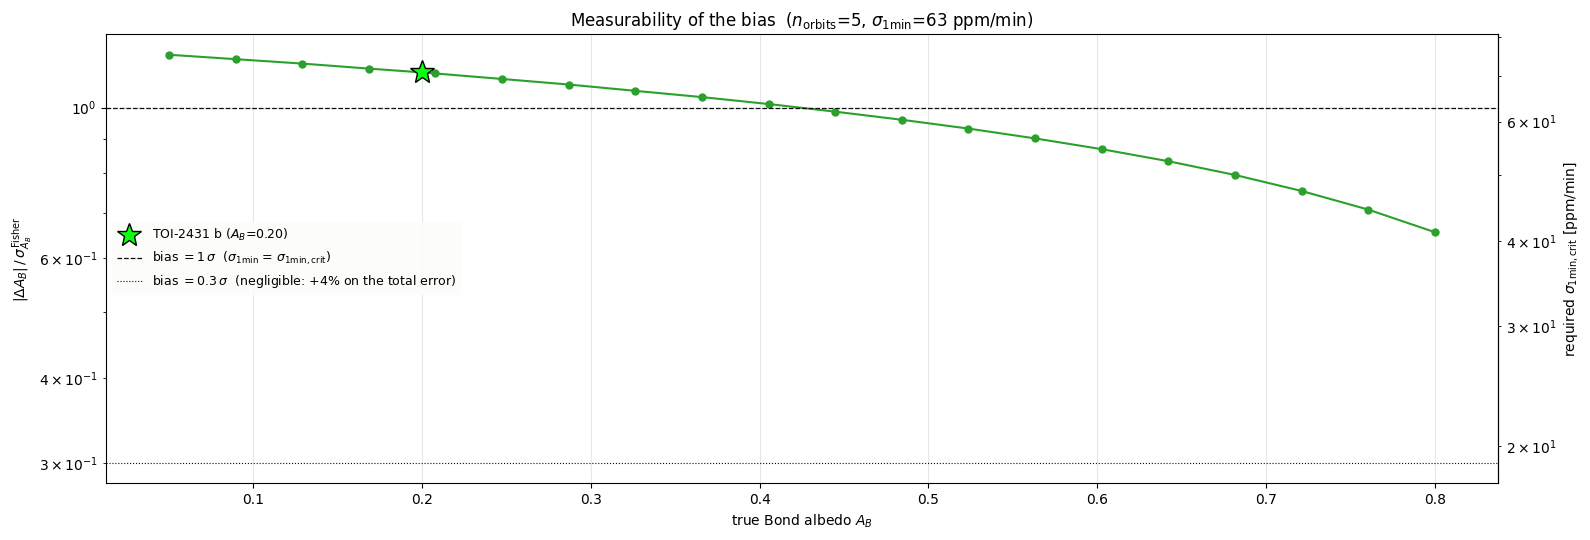

fitted A_B < 0 for true A_B <= 0.05
at TOI-2431 b (A_B=0.20): bias -0.0598,  sigma_A_B = 0.0531  ->  |bias|/sigma = 1.13
   sigma_1min = 62.9 ppm/min,  sigma_1min_crit = 70.9 ppm/min  ->  0.9x finer photometry, or 4 orbits instead of 5, before the bias reaches 1 sigma


In [11]:
# Vary the TRUE Bond albedo and refit the naive model at each value (single target geometry,
# free baseline; free_offset=False is not meaningful here -- see 2.). Bias = A_fit - A_B_true.
A_B_grid = np.unique(np.concatenate([np.linspace(0.05, 0.80, 20), [A_B_true]]))

# naive fit at each true A_B (A_fit in A_B_FIT_BOUNDS, so it can go below the physical floor 0) plus its Fisher sigma, evaluated at the FIT, where the naive posterior sits
sweep = bias_vs_true_AB(cfg, A_B_grid, redist=False)["naive"]
bias_abs, sigma_fisher = sweep["bias_A_B"], sweep["sigma_A_B"]
bias_rel = 100. * bias_abs / A_B_grid
bias_sigma, sigma_1min_crit = measurability(bias_abs, sigma_fisher, cfg.sigma_1min)   # |bias| in units of sigma_A_B at the CURRENT sigma_1min, and the per-minute precision at which |bias| = sigma_A_B
i0 = int(np.argmin(np.abs(A_B_grid - A_B_true)))   # nominal target point

below = A_B_grid + bias_abs < 0.   # fits below the physical floor A_B = 0
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))   # absolute | relative
for a_, y, y0, ylab, ttl, col in ((ax[0], bias_abs, -A_B_grid, r"absolute bias  $A_{B,\rm fit}-A_B$", "Absolute", "C0"),
                                  (ax[1], bias_rel, np.full(len(A_B_grid), -100.), r"relative bias  $(A_{B,\rm fit}-A_B)/A_B$ [%]", "Relative", "C3")):
    a_.axhline(0, color="k", lw=.8)
    a_.plot(A_B_grid, y, "o-", color=col, lw=1.5, ms=5)
    a_.plot(A_B_grid[i0], y[i0], "*", color="#0cff0c", ms=18, mec="k", label=f"{planet.name} ($A_B$={A_B_true:.2f})")
    if below.any():   # the fitted A_B = 0 reference line (Delta A_B = -A_B), as on the bias maps; the y range stays the data's
        lim = a_.get_ylim(); a_.plot(A_B_grid, y0, zorder=1.5, label=r"fitted $A_B$ = 0  ($\Delta A_B = -A_B$)", **FIT_ZERO); a_.set_ylim(lim)
    a_.set_xlabel(r"true Bond albedo $A_B$"); a_.set_ylabel(ylab)
    a_.set_title(ttl + r" bias in recovered $A_B$"); a_.grid(alpha=.3); a_.legend()
fig.suptitle("Bias in recovered $A_B$ from neglecting hyperillumination, vs. the true $A_B$", y=1.02)
fig.tight_layout()
plt.show()

# Is the bias measurable? |bias| / sigma_A_B, with sigma_A_B from the inverted Fisher matrix (offset marginalised, as in the fit).
# The right axis is the SAME curve scaled by cfg.sigma_1min: the per-minute precision at which the bias would be a 1-sigma effect.
# So the dashed horizontal line is where the instrument actually sits - the curve crossing it is the point where hyperillumination stops being ignorable.
fig, a_ = plt.subplots(figsize=(16, 5.5))
measurability_panel(a_, A_B_grid, [(bias_sigma, "o-", "C2", None)], i0, cfg, f"{planet.name} ($A_B$={A_B_true:.2f})",
                    r"$|\Delta A_B|\,/\,\sigma_{A_B}^{\rm Fisher}$",
                    r"Measurability of the bias  ($n_{\rm orbits}$=%d, $\sigma_{1\rm min}$=%.0f ppm/min)" % (cfg.n_orbits, cfg.sigma_1min))
a_.grid(alpha=.3)
fig.tight_layout()
plt.show()

fac = cfg.sigma_1min / sigma_1min_crit[i0]   # how much finer the photometry must get before the bias is a 1-sigma effect
print(f"fitted A_B < 0 for true A_B <= {A_B_grid[below].max():.2f}" if below.any() else "fitted A_B >= 0 at every true A_B of the grid")
print(f"at {planet.name} (A_B={A_B_true:.2f}): bias {bias_abs[i0]:+.4f},  sigma_A_B = {sigma_fisher[i0]:.4f}  ->  |bias|/sigma = {bias_sigma[i0]:.2f}")
print(f"   sigma_1min = {cfg.sigma_1min:.1f} ppm/min,  sigma_1min_crit = {sigma_1min_crit[i0]:.1f} ppm/min"
      f"  ->  {fac:.1f}x finer photometry, or {fac ** 2 * cfg.n_orbits:.0f} orbits instead of {cfg.n_orbits}, before the bias reaches 1 sigma")


The fit is not bounded by the physical floor (`A_B_FIT_BOUNDS`): at low true $A_B$ the best-fit naive albedo can go below $A_{B,\rm fit} = 0$, where the point-source model needs more absorbed energy than the star delivers to a point. The dash-dot line marks $A_{B,\rm fit} = 0$ (absolute bias $-A_B$, relative bias $-100\%$); below it a retrieval with the physical prior $A_B \in [0, 1]$ would rail at 0, and the bias seen by such a retrieval would saturate there. Whether and below which true $A_B$ the fit crosses it depends on the configuration; the output prints it. So far the bias has been negative throughout, with its magnitude shrinking as $A_B\to1$.

### 4. Bias vs. inclination

The bias maps of `Bias_Maps.ipynb` are computed for a central transit ($i = 90°$). Here the target keeps its own $a/R_\star$, $R_p/R_\star$ and star, and only the inclination is swept (`bias_sweep` with `cfg_with_incl`), from $90°$ down to the lowest inclination at which the occultation still spans `MIN_OCC_BINS` phase bins, including the planet's own $i$ (green star), for the $A_B$-only fit. The sweep is run for MIRI/LRS and for the joint NIRSpec fit at the planet's own noise in each, independent of the `instrument` chosen at the top; the noise level per minute does not change with $i$.

What to look for: how fast the bias shrinks from a central transit towards a grazing one, and how much more slowly the expected evidence $\chi^2_{\min}/2$ falls: the bias is the part of the mismatch the fit absorbs, the evidence the part it cannot. The value at $i = 90°$ is what the maps show at the planet's position (up to their fixed $R_p/R_\star$); the difference to the green star is the error of reading an inclined planet off the map.

Why the sweep stops short of the grazing limit $b = 1 - R_p/R_\star$: close to it the occultation lasts only two or three phase bins, and the fitted values then depend on where the bin edges fall, i.e. on `n_bins`, more than on the inclination. The cell after the sweep refits the lowest inclination of the grid and the planet's own with five times finer bins. If the lowest point moves much more than the planet's own, raise `MIN_OCC_BINS`.

inclination grid: 68-90 deg (occultation >= 3 of 27 bins below 90 deg; grazing below 61.9 deg)



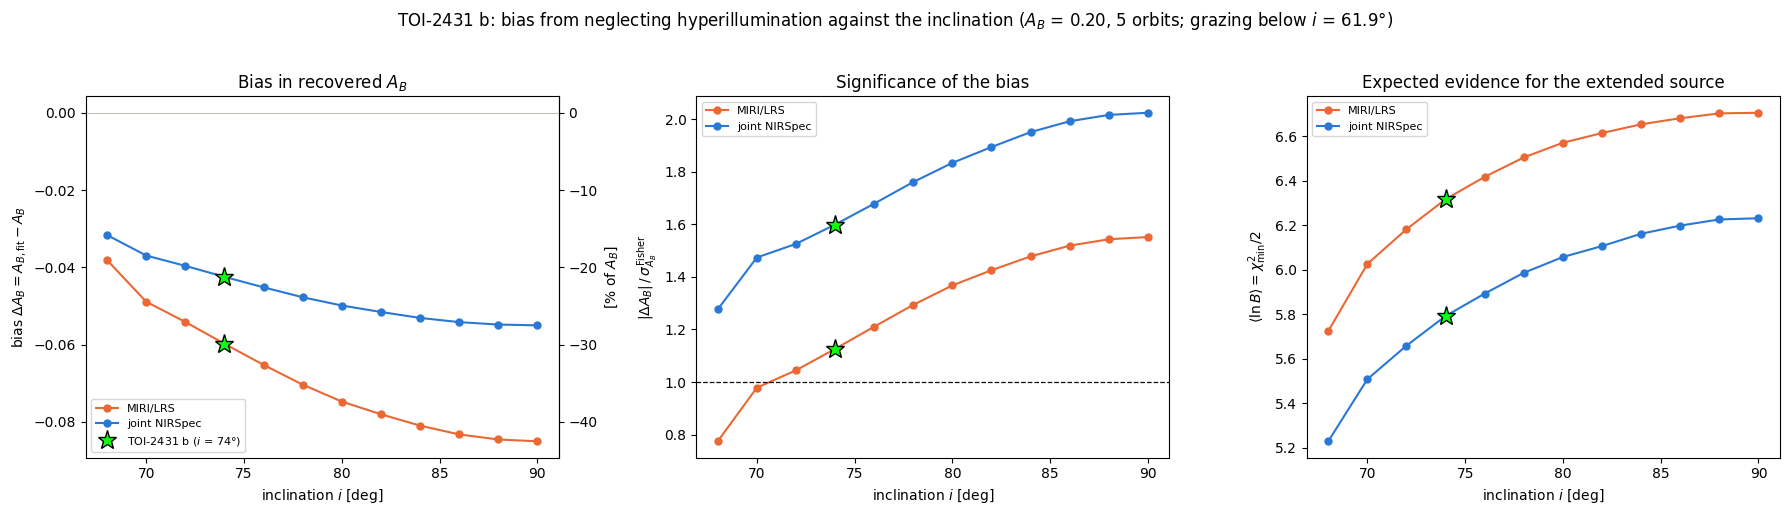

TOI-2431 b, MIRI/LRS  (value = inclination [deg])
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
    90    0.115   -0.085 0.05478       1.552 13.41     6.707
    88   0.1155 -0.08453 0.05478       1.543 13.41     6.704
    86   0.1168 -0.08321 0.05479       1.519 13.36     6.682
    84   0.1191 -0.08095 0.05477       1.478 13.31     6.655
    82    0.122   -0.078 0.05473       1.425 13.23     6.615
    80   0.1253 -0.07472 0.05464       1.368 13.14     6.572
    78   0.1297 -0.07034 0.05438       1.294 13.01     6.506
    76   0.1348 -0.06524 0.05389       1.211 12.84     6.418
    74   0.1402 -0.05978 0.05308       1.126 12.64     6.318
    72   0.1459 -0.05413 0.05182       1.045 12.37     6.183
    70   0.1511  -0.0489 0.04997      0.9786 12.05     6.026
    68   0.1618 -0.03816 0.04925      0.7748 11.45     5.724 

TOI-2431 b, joint NIRSpec  (value = inclination [deg])
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
    90    0.145   -0.055 0.02717       

In [12]:
# Modes of the sweeps (sections 4 and 5): MIRI/LRS and the joint NIRSpec fit, each at the planet's own noise; independent of `instrument` above
SWEEP_MODES = {"MIRI/LRS": "MIRI/LRS", "joint NIRSpec": tuple(JWST_BANDS[:2])}
kw_sweep = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)
sweep_cfgs = {label: retrieval_cfg(cfg, planet, ins) for label, ins in SWEEP_MODES.items()}

# Lowest inclination of the sweep: the occultation (as long as the transit on a circular orbit) must still span MIN_OCC_BINS phase bins; closer to grazing the fit depends on n_bins (checked in the next cell)
MIN_OCC_BINS = 3
i_graze = np.degrees(np.arccos((1. - planet.r1 / planet.r2) / (planet.R / planet.r2)))   # b = 1 - Rp/R*: below it the occultation is grazing
i_whole = np.arange(np.ceil(i_graze), 90.5, 1.)   # whole degrees
long_enough = (transit_duration_t14(planet.period, planet.R / planet.r2, planet.r1 / planet.r2, pd.Series(i_whole)) >= MIN_OCC_BINS * planet.period * 24. / cfg.n_bins).to_numpy()
if not long_enough.any(): raise ValueError(f"the occultation spans fewer than {MIN_OCC_BINS} of {cfg.n_bins} bins even at i = 90 deg: lower MIN_OCC_BINS or raise n_bins")
i_min = i_whole[np.argmax(long_enough)]
if planet.incl < i_min: print(f"NOTE: the planet's own i = {planet.incl:g} deg is below the cut ({i_min:g} deg), so its own point depends on n_bins")
incl_grid = np.unique(np.concatenate([np.arange(90., i_min - 0.5, -2.), [i_min, planet.incl]]))[::-1]
print(f"inclination grid: {i_min:g}-90 deg (occultation >= {MIN_OCC_BINS} of {cfg.n_bins} bins below 90 deg; grazing below {i_graze:.1f} deg)\n")
sweeps_i = {label: bias_sweep(c, A_B_true, incl_grid, cfg_with_incl, models=("naive",), **kw_sweep) for label, c in sweep_cfgs.items()}

fig, _ = plot_bias_sweep(sweeps_i, A_B_true, r"inclination $i$ [deg]", joint=False, mark=planet.incl, mark_label=f"{planet.name} ($i$ = {planet.incl:g}°)",
                         title=f"{planet.name}: bias from neglecting hyperillumination against the inclination ($A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits; grazing below $i$ = {i_graze:.1f}°)")
plt.show()
for label, t in sweeps_i.items():
    print(f"{planet.name}, {label}  (value = inclination [deg])")
    print(t[["value", "A_B_fit", "bias", "sigma", "bias_sigma", "chi2", "lnB_mean"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"), "\n")

In [13]:
# Is the lowest inclination far enough from grazing? The A_B-only fit at the baseline binning and at FINE_BINS, at the lowest inclination of the grid and at the planet's own: near grazing
# the occultation covers few bins and the fit depends on where their edges fall. Raise MIN_OCC_BINS in the sweep cell if the lowest point moves much more than the planet's own.
FINE_BINS = 5 * cfg.n_bins
for label, c in sweep_cfgs.items():
    for i_ in (incl_grid.min(), planet.incl):
        c_i = [cfg_with_incl(det, i_) for det in c] if is_detector_set(c) else cfg_with_incl(c, i_)
        t = bias_sweep(c_i, A_B_true, (cfg.n_bins, FINE_BINS), lambda c_, nb: replace(c_, n_bins=int(nb)), models=("naive",), **kw_sweep)
        print(f"{planet.name}, {label}, i = {i_:g} deg: bias {t['bias'][0]:+.4f} ({cfg.n_bins} bins) -> {t['bias'][1]:+.4f} ({FINE_BINS} bins), {100 * (t['bias'][1] / t['bias'][0] - 1):+.1f} %;  "
              f"sigma {t['sigma'][0]:.4f} -> {t['sigma'][1]:.4f}")

TOI-2431 b, MIRI/LRS, i = 68 deg: bias -0.0382 (27 bins) -> -0.0391 (135 bins), +2.4 %;  sigma 0.0492 -> 0.0488
TOI-2431 b, MIRI/LRS, i = 74 deg: bias -0.0598 (27 bins) -> -0.0626 (135 bins), +4.7 %;  sigma 0.0531 -> 0.0501
TOI-2431 b, joint NIRSpec, i = 68 deg: bias -0.0316 (27 bins) -> -0.0321 (135 bins), +1.3 %;  sigma 0.0248 -> 0.0246
TOI-2431 b, joint NIRSpec, i = 74 deg: bias -0.0425 (27 bins) -> -0.0434 (135 bins), +2.2 %;  sigma 0.0266 -> 0.0250


**A planet read off the map against its own inclination.** The same two-point comparison for the paper planets with the largest impact parameters (`check_planets`, $b > 0.5$), in the first mode of `SWEEP_MODES`: the $A_B$-only fit at $i = 90°$, where the map places the planet, and at its own inclination. The printed relative biases show how much of the difference between a map value and the per-planet fit is the inclination alone. The cell also prints how many phase bins the occultation spans at the planet's own inclination: below `MIN_OCC_BINS` the own-inclination value depends on `n_bins` (see the check above).

In [14]:
check_planets = ("TOI-2431 b", "TOI-2260 b", "Kepler-78 b")   # the paper planets with b > 0.5, whose map value (i = 90 deg) overstates their own-geometry bias
mode0 = next(iter(SWEEP_MODES))
for nm in check_planets:
    pl_ = hi_planets_by_name(nm)
    t = bias_sweep(retrieval_cfg(cfg, pl_, SWEEP_MODES[mode0]), A_B_true, (90., pl_.incl), cfg_with_incl, models=("naive",), **kw_sweep)
    b = pl_.R / pl_.r2 * np.cos(np.radians(pl_.incl))
    occ_bins = transit_duration_t14(pl_.period, pl_.R / pl_.r2, pl_.r1 / pl_.r2, pd.Series([pl_.incl])).iloc[0] / (pl_.period * 24. / cfg.n_bins)   # occultation length at its own i [phase bins]
    print(f"{nm} ({mode0}, a/R* = {pl_.R / pl_.r2:.2f}, b = {b:.2f}, occultation {occ_bins:.1f} of {cfg.n_bins} bins): bias {t['bias'][0]:+.4f} ({100 * t['bias'][0] / A_B_true:+.0f} %) at i = 90 deg,  {t['bias'][1]:+.4f} ({100 * t['bias'][1] / A_B_true:+.0f} %) at its own i = {pl_.incl:g} deg;  "
          f"|bias|/sigma {t['bias_sigma'][0]:.2f} -> {t['bias_sigma'][1]:.2f}")

TOI-2431 b (MIRI/LRS, a/R* = 2.08, b = 0.57, occultation 3.8 of 27 bins): bias -0.0850 (-42 %) at i = 90 deg,  -0.0598 (-30 %) at its own i = 74 deg;  |bias|/sigma 1.55 -> 1.13
TOI-2260 b (MIRI/LRS, a/R* = 2.22, b = 0.77, occultation 2.8 of 27 bins): bias -0.0770 (-39 %) at i = 90 deg,  -0.0282 (-14 %) at its own i = 69.7 deg;  |bias|/sigma 0.53 -> 0.21
Kepler-78 b (MIRI/LRS, a/R* = 2.70, b = 0.69, occultation 2.5 of 27 bins): bias -0.0417 (-21 %) at i = 90 deg,  -0.0202 (-10 %) at its own i = 75.2 deg;  |bias|/sigma 0.14 -> 0.07


### 5. Bias vs. the limb darkening $u_{\rm bol}$ of the irradiance

The bolometric linear limb darkening $u_{\rm bol}$ of the stellar disc enters only the extended-source truth: the point-source models have no $u_{\rm bol}$. The sweep (`bias_sweep` with `cfg_with_u_bol`) therefore changes the truth alone and refits it, for the $A_B$-only fit in the two modes of section 4; the baseline value is the green star.

What to look for: how little the bias moves across the range of plausible bolometric limb-darkening coefficients, and the somewhat stronger dependence of the expected evidence (a more limb-darkened star puts less light into the penumbra).

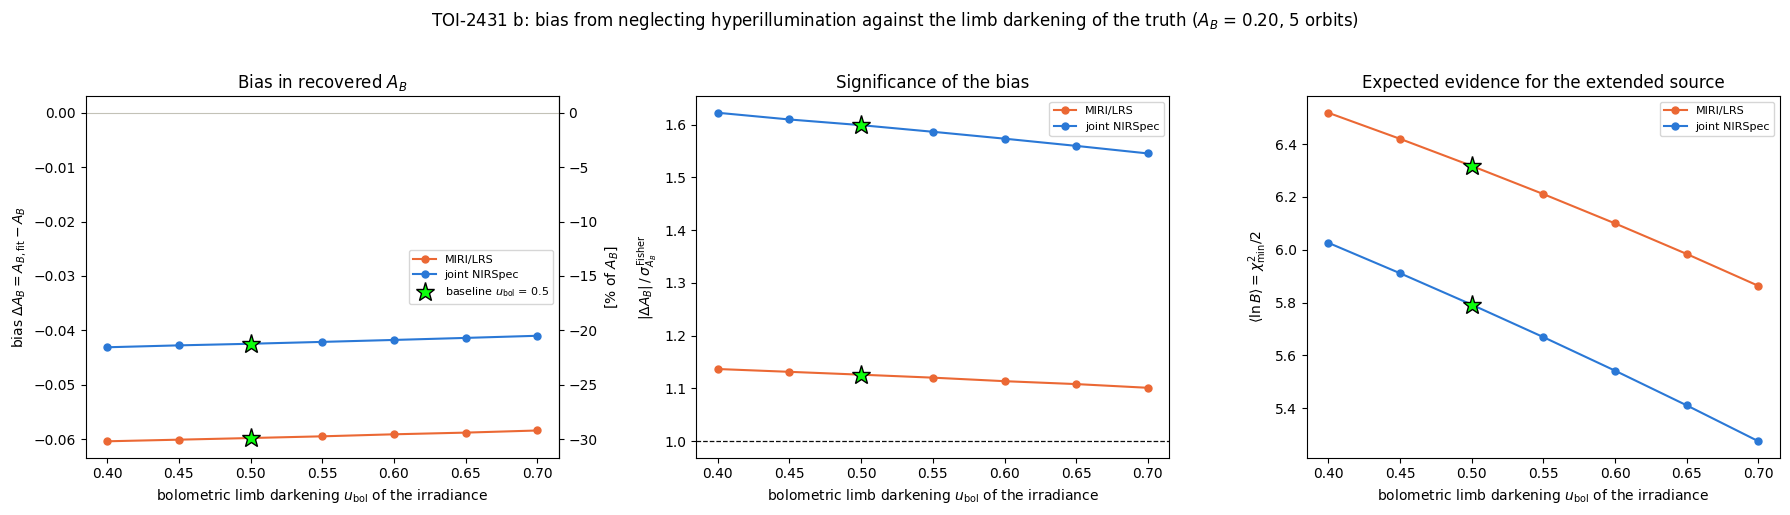

TOI-2431 b, MIRI/LRS  (value = u_bol)
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
   0.4   0.1396 -0.06038 0.05311       1.137 13.04     6.519
  0.45   0.1399 -0.06008  0.0531       1.132 12.84      6.42
   0.5   0.1402 -0.05978 0.05308       1.126 12.64     6.318
  0.55   0.1405 -0.05946 0.05307       1.121 12.42     6.211
   0.6   0.1409 -0.05909 0.05305       1.114  12.2       6.1
  0.65   0.1412 -0.05878 0.05304       1.108 11.97     5.984
   0.7   0.1416 -0.05839 0.05302       1.101 11.73     5.863 

TOI-2431 b, joint NIRSpec  (value = u_bol)
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
   0.4   0.1569  -0.0431 0.02657       1.622 12.05     6.026
  0.45   0.1573 -0.04275 0.02656        1.61 11.82     5.911
   0.5   0.1575 -0.04245 0.02655       1.599 11.58     5.792
  0.55   0.1579 -0.04211 0.02655       1.586 11.34     5.669
   0.6   0.1582 -0.04175 0.02654       1.573 11.08     5.542
  0.65   0.1586 -0.04138 0.02653       1.559 10.82      5.41
  

In [15]:
u_bol_grid = np.unique(np.round(np.concatenate([np.arange(0.40, 0.701, 0.05), [u_bol]]), 6))
sweeps_u = {label: bias_sweep(c, A_B_true, u_bol_grid, cfg_with_u_bol, models=("naive",), **kw_sweep) for label, c in sweep_cfgs.items()}

fig, _ = plot_bias_sweep(sweeps_u, A_B_true, r"bolometric limb darkening $u_{\rm bol}$ of the irradiance", joint=False, mark=u_bol, mark_label=f"baseline $u_{{\\rm bol}}$ = {u_bol:g}",
                         title=f"{planet.name}: bias from neglecting hyperillumination against the limb darkening of the truth ($A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits)")
plt.show()
for label, t in sweeps_u.items():
    print(f"{planet.name}, {label}  (value = u_bol)")
    print(t[["value", "A_B_fit", "bias", "sigma", "bias_sigma", "chi2", "lnB_mean"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"), "\n")

**The host's own $u_{\rm bol}$.** The baseline $u_{\rm bol}$ is the bolometric coefficient of the host of TOI-2431 b; the other hosts of the sample have somewhat more limb-darkened discs (`Stellar Model/LimbDarkening.ipynb`). For the planets of `u_bol_planets`, the $A_B$-only fit with the truth at the baseline $u_{\rm bol}$ and at the host's own value (least-squares linear fit to the PHOENIX bolometric profile, as in `LimbDarkening.ipynb`), in both modes. The printed change of the bias is what adopting one $u_{\rm bol}$ for every host does to that planet's result.

In [16]:
u_bol_planets = ("K2-141 b",)   # hosts whose own u_bol differs from the baseline (LimbDarkening.ipynb)
for nm in u_bol_planets:
    pl_ = hi_planets_by_name(nm)
    u_host = bolometric_ld_profile(pl_, "phoenix")[2]   # least-squares linear coefficient of the host's bolometric profile, PHOENIX grid as in LimbDarkening.ipynb
    for label, ins in SWEEP_MODES.items():
        t = bias_sweep(retrieval_cfg(cfg, pl_, ins), A_B_true, (u_bol, u_host), cfg_with_u_bol, models=("naive",), **kw_sweep)
        print(f"{nm}, {label}: u_bol {u_bol:g} -> {u_host:.3f} (host):  bias {t['bias'][0]:+.4f} -> {t['bias'][1]:+.4f} ({100 * (t['bias'][1] / t['bias'][0] - 1):+.1f} %),  "
              f"sigma {t['sigma'][0]:.4f} -> {t['sigma'][1]:.4f},  <ln B> {t['lnB_mean'][0]:.2f} -> {t['lnB_mean'][1]:.2f}")

K2-141 b, MIRI/LRS: u_bol 0.5 -> 0.563 (host):  bias -0.0637 -> -0.0633 (-0.7 %),  sigma 0.0853 -> 0.0853,  <ln B> 2.06 -> 2.01
K2-141 b, joint NIRSpec: u_bol 0.5 -> 0.563 (host):  bias -0.0424 -> -0.0420 (-1.0 %),  sigma 0.0372 -> 0.0372,  <ln B> 2.58 -> 2.51
